# ATP tennis random walk
## Tasks 3 and 4

We simulated the original random walk on the ATP tennis network from two starting players and investigated why both runs converge to the same stationary distribution.

An arrow goes from the loser to the winner. The dataset pools tour-level results from 2016–2025 and records each directed pair once. We use the original **completed** transition matrix P from Task 1. Its 63 dangling rows use the uniform rule specified in the handout.

**Setup.** This notebook runs from the root of the full project repository. The project’s Python environment is the interpreter at .venv/bin/python on Mac. The cells below import the same functions used by the Python scripts.

**Before running the ranking.** Our Task 2 prediction is that Alexander Zverev will rank highly because he has the most distinct incoming opponents. Djokovic starts in the largest original strongly connected component. Bopanna starts at a dangling player, so his first step is uniform across the network.

### Setup · Import libraries

We import the standard-library tools for finding project files and the libraries for working with arrays and displaying figures.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

### Setup · Find the project scripts

The task files are in the src folder. We add that folder to Python’s import path so the notebook can call the scripts’ functions.

In [2]:
source_dir = Path.cwd() / "src"
if not (source_dir / "task3.py").is_file():
    raise FileNotFoundError("Open the notebook from the root of Computer-Programming-I-Project.")

if str(source_dir) not in sys.path:
    sys.path.insert(0, str(source_dir))

### Setup · Import Task 3 functions

We reuse the saved-network loader, stopping settings, power-iteration runner, and plotting functions from task3.py.

In [3]:
from task3 import (
    MAX_ITERATIONS,
    STARTING_PLAYERS,
    TOLERANCE,
    load_network,
    plot_convergence,
    plot_player_probabilities,
    print_walk_summary,
    run_from_starting_players,
)

### Setup · Load the transition matrix

We load A and the completed P saved by Task 1. The player IDs in nodes.csv tell us which matrix row and column belong to each player. The loader checks the matrix dimensions, matches the player IDs to the indices, and checks that P has nonnegative entries and row sums of one.

In [4]:
adjacency, transition, player_ids = load_network()
names_by_id = {node_id: name for name, node_id in player_ids.items()}

print(f"Players: {len(player_ids):,}")
print(f"Directed match edges: {adjacency.sum():,}")
print(f"Transition matrix shape: {transition.shape}")

Players: 1,191
Directed match edges: 19,986
Transition matrix shape: (1191, 1191)


### Check the transition matrix

We check nonnegativity and row sums in separate cells.

In [5]:
# Check the transition probabilities.
assert np.all(transition >= 0), "P contains a negative or invalid probability."
print("Pass: all entries of P are nonnegative.")

Pass: all entries of P are nonnegative.


In [6]:
# Check the sum of each transition row.
row_sums = transition.sum(axis=1)
bad_rows = np.flatnonzero(~np.isclose(row_sums, 1, atol=1e-12, rtol=0))
assert bad_rows.size == 0, f"P rows do not sum to 1. First affected player IDs: {bad_rows[:5]}"
print("Pass: every row of P sums to 1.")

Pass: every row of P sums to 1.


## Task 3 · Simulate the original walk

We represent the walker by a row vector xₖ. Its entry for a player is the probability of being on that player after k steps. The entries are nonnegative and add up to 1. We chose two initial distributions, each with a 1 at the starting player's index and zeros elsewhere.

- **Novak Djokovic (130)** belongs to the largest strongly connected component of the original match graph. On the first move his probability is divided equally among the 51 players who beat him.
- **Rohan Bopanna (8)** is dangling in the original graph. His first move uses the completed uniform row of P, giving each of the 1,191 players probability 1/1191.

In [7]:
for name in STARTING_PLAYERS:
    player_id = player_ids[name]
    destinations = np.count_nonzero(transition[player_id])
    print(f"{name} (ID {player_id}): {destinations:,} possible destinations at step 1")

Novak Djokovic (ID 130): 51 possible destinations at step 1
Rohan Bopanna (ID 8): 1,191 possible destinations at step 1


### Run the power iteration

At each iteration we take one step by multiplying the current row vector by the transition matrix.

    xₖ₊₁ = xₖ × P

Each player sends their current probability to possible destinations in proportion to their row of P. After k moves the distribution is x₀ × Pᵏ. We compute it by successive updates, saving the starting distribution and every new distribution.

For update k we add up the absolute changes across all players.

    Δₖ = ‖xₖ − xₖ₋₁‖₁ = ∑ⱼ |xₖ[j] − xₖ₋₁[j]|

Absolute values keep gains and losses in different entries from cancelling. We stop at the first Δₖ < 10⁻¹⁰ or after 5,000 updates. The function returns the last vector, update count, full distribution and change histories, and whether the threshold was reached.

In [8]:
print(f"Tolerance: {TOLERANCE:.0e} | Maximum updates: {MAX_ITERATIONS:,}")
runs = run_from_starting_players(transition, player_ids)

Tolerance: 1e-10 | Maximum updates: 5,000


### Check the recorded walk

We verify the saved changes and check whether both runs reached the tolerance.

In [9]:
# Recalculate the L1 changes from the saved history.
for name, result in runs.items():
    recomputed_changes = np.abs(np.diff(result.history, axis=0)).sum(axis=1)
    assert np.array_equal(result.changes, recomputed_changes), f"{name}: saved L1 changes disagree with the history."
print("Pass: recorded L1 changes match consecutive distributions.")

Pass: recorded L1 changes match consecutive distributions.


In [10]:
# Check that each run reached the threshold within the cap.
for name, result in runs.items():
    assert result.converged, f"{name}: the stopping tolerance was not reached in {MAX_ITERATIONS:,} steps."
print("Pass: both runs reached the stopping tolerance.")

Pass: both runs reached the stopping tolerance.


### Report the stopping results

For each start we report whether the tolerance was reached, the number of updates, and the last L1 change. The final L1 gap compares the two full distributions.

In [11]:
print_walk_summary(runs)

Novak Djokovic: 28 steps (threshold reached)
  Players with positive probability after step 1: 51
  Last L1 change: 6.628e-11
Rohan Bopanna: 33 steps (threshold reached)
  Players with positive probability after step 1: 1191
  Last L1 change: 7.305e-11
L1 difference between final distributions: 7.797e-11


### Plot the player probabilities

We use a separate panel for each starting player and the same vertical scale in both panels. Each line shows the probability on one representative player through the run. The scale is logarithmic above 10⁻⁷ and linear between zero and 10⁻⁷, so zero probabilities appear at zero. The scale is logarithmic above 10⁻⁷ and linear between zero and 10⁻⁷, so zero probabilities appear at zero.

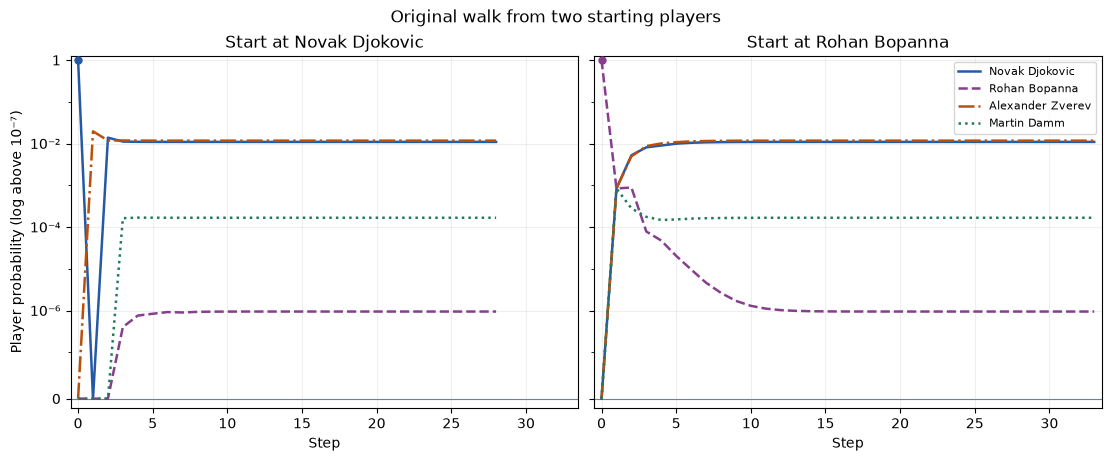

In [12]:
trajectory_figure = plot_player_probabilities(runs, player_ids)
display(trajectory_figure)
plt.close(trajectory_figure)

### Plot convergence

We plot the L1 change after each update. The dotted line marks the stopping tolerance. The labelled dots show the first update below it. An L1 change can exceed 1 because it sums both the probability lost by some players and the probability gained by others.

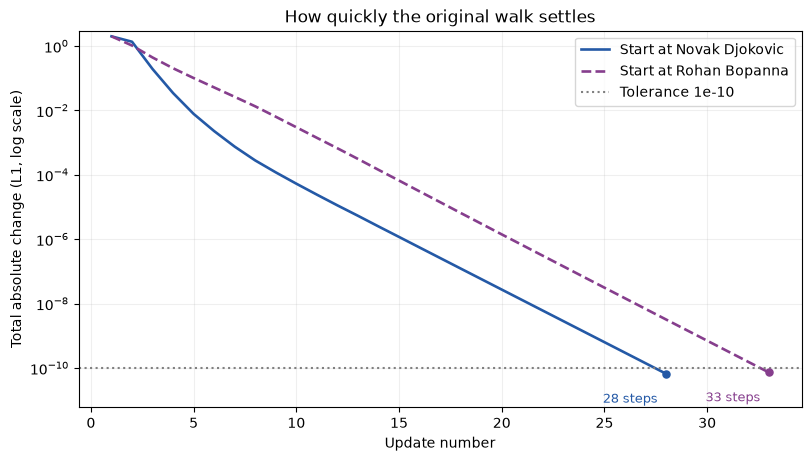

In [13]:
convergence_figure = plot_convergence(runs, tolerance=TOLERANCE)
display(convergence_figure)
plt.close(convergence_figure)

**What we observed.** The upper figure tracks Djokovic and Bopanna (the two starts), Zverev (our predicted leader), and Damm (a player with a lower stationary score). The zero tick shows that some players have zero probability in the early steps. The panels show different early trajectories, followed by the same levels for the plotted players. The lower figure tracks the total change across all 1,191 players. Djokovic's run met the threshold in **28 updates** (6.628 × 10⁻¹¹ on the last update). Bopanna's met it in **33 updates** (7.305 × 10⁻¹¹). The final vectors differ by 7.797 × 10⁻¹¹ in L1 distance. We observed no sustained oscillation.

**How the structure relates to the result.** Djokovic starts by passing probability to recorded opponents. Bopanna's first step spreads probability throughout the graph, including players outside the largest original component. The different early distributions explain why the starting player can affect the convergence history. The uniform rows let the walker leave dangling players. In Task 4 we show why all starting distributions converge to the same limit in the completed walk.

## Task 4 · Find and check a stationary distribution

A distribution π is **stationary** when one more step leaves every player's probability unchanged: π × P = π. Taking the transpose of both sides gives Pᵀ × πᵀ = πᵀ. NumPy gives right eigenvectors as columns, so we take a column from `eig(P.T)` for eigenvalue 1 and normalize it to sum to 1.

We check that the candidate is real, nonnegative and sums to 1. The **stationary residual** π × P − π measures how much one more step would change it. We also compare the candidate with both Task 3 results.

In [14]:
from task4 import (
    print_graph_evidence,
    print_spectrum,
    print_stationary_equations,
    print_top_players,
    print_walk_agreement,
    stationary_distribution,
)

### Find and normalize the eigenvector

We use the helper from task4.py to find the eigenvector at eigenvalue 1, normalize it as a probability vector, and calculate the residual. It also returns the spectrum for the final check.

In [15]:
stationary, eigenvalues, at_one, residual = stationary_distribution(transition)

### Verify the stationary distribution

We check that the probabilities sum to one and are nonnegative, then report the L1 norm of the residual. A small residual means one more step would barely change the result.

In [16]:
# Check for negative probabilities.
assert np.all(stationary >= 0), "The stationary vector contains a negative or invalid probability."
print(f"Pass: minimum stationary probability = {stationary.min():.3e}.")

Pass: minimum stationary probability = 4.730e-07.


In [17]:
# Check that the stationary vector contains one unit of probability.
stationary_total = stationary.sum()
assert np.isclose(stationary_total, 1, atol=1e-12, rtol=0), f"The stationary vector sums to {stationary_total}, expected 1."
print(f"Pass: stationary probability sum = {stationary_total:.12f}.")

Pass: stationary probability sum = 1.000000000000.


In [18]:
# Check the size of π × P − π.
residual_size = np.abs(residual).sum()
assert residual_size < 1e-12, f"The L1 stationary residual {residual_size:.3e} exceeds the numerical tolerance."
print(f"Pass: the L1 stationary residual is {residual_size:.3e}.")

Pass: the L1 stationary residual is 7.752e-16.


### Compare the two methods

We compare the eigenvector result with the final vector from each Task 3 run. We also list the five players with the highest stationary probabilities.

In [19]:
# Check agreement with each final power-iteration vector.
# This is a comparison tolerance for the final vectors.
for name, result in runs.items():
    distance = np.abs(result.final - stationary).sum()
    assert distance < 1e-9, f"{name}: the final vector differs from the eigenvector by {distance:.3e} in L1."
print("Pass: both runs agree with the eigenvector result within 1e-9 in L1.")

Pass: both runs agree with the eigenvector result within 1e-9 in L1.


In [20]:
print_walk_agreement(stationary, runs)
print_top_players(stationary, names_by_id)

L1 distance to Task 3's Novak Djokovic result: 5.901e-11
L1 distance to Task 3's Rohan Bopanna result: 6.495e-11

Top five players in the original walk:
1. Alexander Zverev: 1.173560%
2. Novak Djokovic: 1.093975%
3. Daniil Medvedev: 1.069112%
4. Andrey Rublev: 1.057069%
5. Taylor Fritz: 1.047068%


### Two stationary equations by hand

We worked out each player's stationary probability by adding the probability flowing in along the match arrows and the shared contribution from the 63 dangling players. A player with out-degree d sends a fraction 1/d of their probability along each outgoing match arrow. A dangling player sends 1/1191 of their probability to each of the 1,191 players.

We call the shared contribution to each player c.

    c = sum of the 63 dangling players’ stationary probabilities / 1191
      ≈ 4.73020 × 10⁻⁷

**Rohan Bopanna.** Hong Chung's only outgoing match arrow points to Bopanna. We add Hong Chung's full stationary probability and c.

    π(Bopanna) = π(Hong Chung) / 1 + c
               ≈ 4.73020 × 10⁻⁷ + 4.73020 × 10⁻⁷
               ≈ 9.46040 × 10⁻⁷

**Martin Damm.** The arrows into Damm come from Zhizhen Zhang, Tommy Paul, and Darwin Blanch. Their out-degrees are 56, 76, and 4.

    π(Damm) = π(Zhang)/56 + π(Paul)/76 + π(Blanch)/4 + c
            ≈ 0.002576836/56 + 0.007789578/76
              + 0.00007142946/4 + 0.000000473020
            ≈ 0.0001668398

These are incoming probabilities, so we used each player's column of the transition matrix.

In [21]:
print_stationary_equations(adjacency, stationary, player_ids, names_by_id)


Stationary equation for Rohan Bopanna:
  Hong Chung: 4.730201647e-07 / 1 = 4.730201647e-07
  Uniform contribution from dangling players: 4.730201647e-07
  Sum: 9.460403293e-07  |  Eigenvector entry: 9.460403293e-07

Stationary equation for Martin Damm:
  Zhizhen Zhang: 2.576835729e-03 / 56 = 4.601492374e-05
  Tommy Paul: 7.789577971e-03 / 76 = 1.024944470e-04
  Darwin Blanch: 7.142945642e-05 / 4 = 1.785736411e-05
  Uniform contribution from dangling players: 4.730201647e-07
  Sum: 1.668397550e-04  |  Eigenvector entry: 1.668397550e-04


### Why the two runs agree

We checked the support graph of P, meaning the arrows for all **positive** entries of the completed matrix. In the original graph, the 63 dangling players were singleton closed components. With the uniform rows, every one of them can now move to any player. The code below checks that Djokovic reaches everyone in P, and that everyone can reach Djokovic by reversing the arrows and searching from him. Together these checks show that any player can reach any other via Djokovic. The completed walk has one closed class containing all players, so there are no separate closed classes that could support different stationary distributions.

We also check two return paths already present in A: Djokovic → Nadal → Djokovic (2 steps), and Djokovic → Zverev → Federer → Djokovic (3 steps). The period must divide both 2 and 3, so it is 1. Since the completed graph is irreducible, this makes the whole chain **aperiodic**.

In [22]:
print_graph_evidence(adjacency, transition, player_ids)


Djokovic reaches 1191/1191 players in P.
1191/1191 players can reach Djokovic in P.
2-step return: Novak Djokovic -> Rafael Nadal -> Novak Djokovic
3-step return: Novak Djokovic -> Alexander Zverev -> Roger Federer -> Novak Djokovic
One closed class in P contains every player, so the stationary distribution is unique.
The 2- and 3-step returns have gcd 1, so every starting distribution converges.


### Inspect the eigenvalues

We sort the eigenvalues by absolute value. We check for values near −1 because an eigenvalue of −1 can produce a persistent alternating mode.

In [23]:
print_spectrum(eigenvalues, at_one)


Leading eigenvalues by modulus:
  +1.00000000 +0.00000000i  |lambda| = 1.00000000
  +0.46951796 +0.00438091i  |lambda| = 0.46953840
  +0.46951796 -0.00438091i  |lambda| = 0.46953840
  -0.34012954 +0.00000000i  |lambda| = 0.34012954
  +0.32436331 +0.07093992i  |lambda| = 0.33203016
Largest modulus other than 1: 0.46953840
Eigenvalues near -1: 0


### Interpretation

- **Uniqueness and convergence are separate claims.** Irreducibility of this finite chain gives a unique stationary distribution. Aperiodicity then guarantees convergence to it from every starting player. This is the reason the result holds beyond the two starting players we tested.
- **The spectrum agrees with what we observed.** P and Pᵀ have the same eigenvalues. We find one eigenvalue at 1. The largest remaining modulus is about **0.46954**, from the pair 0.46952 ± 0.00438i. All the other modes decay. There is no eigenvalue near −1 and no sustained alternation in the runs.
- **The original-walk ranking supports the prediction.** Zverev is first with a stationary probability of about **1.1736%**. The percentage is the model's long-run share of probability on Zverev. Repeated wins, surfaces and scores were collapsed or omitted when the dataset was prepared.

### Sources

- IE University. [*Network Centrality and PageRank Using Matrices in Python*](https://blackboard.ie.edu/ultra/courses/_161148_1/file/_3020218_1?courseId=_161148_1), §§ 2.3–2.4.
- Sackmann, Jeff. [*ATP Tennis Rankings, Results, and Stats*](https://github.com/JeffSackmann/tennis_atp). Tennis Abstract. The IE teaching team prepared the [course ATP dataset](https://github.com/daniprec/BAM-CPI-LA-Networks/tree/2109df87176f730065237d42f76675149ff98166/data/atp_tennis).